<a href="https://colab.research.google.com/github/kirti73/AI_lab/blob/main/1BF24CS140_PSO_LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Load Dataset and Define Fitness Function
We will load a dataset with multiple features (e.g., the Wine dataset) and define a fitness function that trains a machine learning model on a subset of features and returns its cross-validation accuracy. Our goal is to maximize accuracy (or minimize error) while potentially minimizing the number of selected features.

In [1]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# Load dataset
data = load_wine()
X, y = data.data, data.target
feature_names = data.feature_names
n_features = X.shape[1]

print(f"Dataset loaded with {X.shape[0]} samples and {n_features} features.")

Dataset loaded with 178 samples and 13 features.


### 2. Implement the Binary PSO Algorithm for Feature Selection
In feature selection, a feature is either selected (1) or not selected (0). We implement Binary PSO (BPSO) where velocity represents the probability of a feature being selected (passed through a sigmoid function).

In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def evaluate_fitness(particle, X, y):
    # If no features are selected, return 0 fitness
    if np.sum(particle) == 0:
        return 0.0

    # Select features indicated by the particle
    selected_features = np.where(particle == 1)[0]
    X_subset = X[:, selected_features]

    # Use Random Forest Classifier with 3-fold cross-validation
    clf = RandomForestClassifier(n_estimators=50, random_state=42)
    scores = cross_val_score(clf, X_subset, y, cv=3)

    # Fitness can be accuracy, optionally penalized by the number of features to keep it small
    accuracy = scores.mean()
    feature_penalty = 0.01 * (np.sum(particle) / len(particle))
    fitness = accuracy - feature_penalty
    return fitness

# PSO Parameters
n_particles = 20
max_iter = 30
w = 0.5  # Inertia weight
c1 = 1.5 # Cognitive coefficient
c2 = 1.5 # Social coefficient

# Initialize particles (positions and velocities)
# Position: binary array of shape (n_particles, n_features)
np.random.seed(42)
particles = np.random.randint(2, size=(n_particles, n_features))
velocities = np.random.uniform(-4, 4, size=(n_particles, n_features))

# Personal best positions and scores
pbest_position = np.copy(particles)
pbest_fitness = np.array([evaluate_fitness(p, X, y) for p in particles])

# Global best position and score
gbest_idx = np.argmax(pbest_fitness)
gbest_position = np.copy(pbest_position[gbest_idx])
gbest_fitness = pbest_fitness[gbest_idx]

# Track progress
history = [gbest_fitness]

# Main PSO Loop
for iteration in range(max_iter):
    for i in range(n_particles):
        # Update velocity
        r1, r2 = np.random.rand(n_features), np.random.rand(n_features)
        cognitive = c1 * r1 * (pbest_position[i] - particles[i])
        social = c2 * r2 * (gbest_position - particles[i])
        velocities[i] = w * velocities[i] + cognitive + social

        # Clamp velocities to prevent saturation
        velocities[i] = np.clip(velocities[i], -6, 6)

        # Update position using Sigmoid function
        probs = sigmoid(velocities[i])
        particles[i] = (np.random.rand(n_features) < probs).astype(int)

        # Evaluate fitness
        fitness = evaluate_fitness(particles[i], X, y)

        # Update personal best
        if fitness > pbest_fitness[i]:
            pbest_fitness[i] = fitness
            pbest_position[i] = np.copy(particles[i])

    # Update global best
    current_gbest_idx = np.argmax(pbest_fitness)
    if pbest_fitness[current_gbest_idx] > gbest_fitness:
        gbest_fitness = pbest_fitness[current_gbest_idx]
        gbest_position = np.copy(pbest_position[current_gbest_idx])

    history.append(gbest_fitness)
    print(f"Iteration {iteration+1:02d}/{max_iter} - Best Fitness: {gbest_fitness:.4f}")

Iteration 01/30 - Best Fitness: 0.9545
Iteration 02/30 - Best Fitness: 0.9602
Iteration 03/30 - Best Fitness: 0.9602
Iteration 04/30 - Best Fitness: 0.9602
Iteration 05/30 - Best Fitness: 0.9602
Iteration 06/30 - Best Fitness: 0.9602
Iteration 07/30 - Best Fitness: 0.9602
Iteration 08/30 - Best Fitness: 0.9602
Iteration 09/30 - Best Fitness: 0.9602
Iteration 10/30 - Best Fitness: 0.9602
Iteration 11/30 - Best Fitness: 0.9602
Iteration 12/30 - Best Fitness: 0.9602
Iteration 13/30 - Best Fitness: 0.9602
Iteration 14/30 - Best Fitness: 0.9602
Iteration 15/30 - Best Fitness: 0.9602
Iteration 16/30 - Best Fitness: 0.9602
Iteration 17/30 - Best Fitness: 0.9602
Iteration 18/30 - Best Fitness: 0.9602
Iteration 19/30 - Best Fitness: 0.9602
Iteration 20/30 - Best Fitness: 0.9602
Iteration 21/30 - Best Fitness: 0.9602
Iteration 22/30 - Best Fitness: 0.9602
Iteration 23/30 - Best Fitness: 0.9602
Iteration 24/30 - Best Fitness: 0.9602
Iteration 25/30 - Best Fitness: 0.9602
Iteration 26/30 - Best Fi

### 3. Display Results and Feature Subset Comparison

=== RESULTS ===
Baseline Accuracy (All 13 features): 0.9327
Optimized Accuracy (Selected 8 features): 0.9664
Selected Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'flavanoids', 'hue', 'proline']


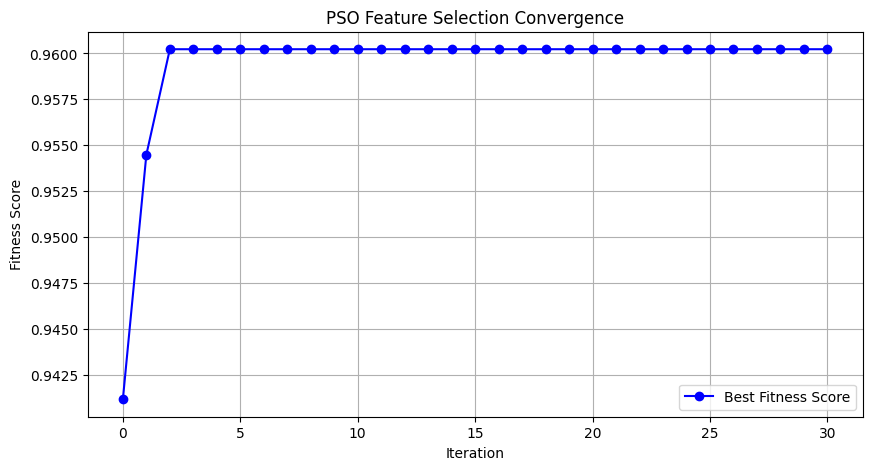

In [3]:
# Evaluate the baseline performance with all features
all_features_mask = np.ones(n_features, dtype=int)
baseline_accuracy = evaluate_fitness(all_features_mask, X, y) + 0.01  # Remove penalty for actual accuracy comparison

# Evaluate selected subset accuracy (excluding penalty)
selected_indices = np.where(gbest_position == 1)[0]
selected_features = [feature_names[i] for i in selected_indices]
clf = RandomForestClassifier(n_estimators=50, random_state=42)
selected_accuracy = cross_val_score(clf, X[:, selected_indices], y, cv=3).mean()

print("=== RESULTS ===")
print(f"Baseline Accuracy (All {n_features} features): {baseline_accuracy:.4f}")
print(f"Optimized Accuracy (Selected {len(selected_indices)} features): {selected_accuracy:.4f}")
print(f"Selected Features: {selected_features}")

# Plot Fitness Convergence
plt.figure(figsize=(10, 5))
plt.plot(history, marker='o', color='b', label='Best Fitness Score')
plt.title('PSO Feature Selection Convergence')
plt.xlabel('Iteration')
plt.ylabel('Fitness Score')
plt.grid(True)
plt.legend()
plt.show()

```markdown
## Pseudocode of the Binary PSO (BPSO) Algorithm for Feature Selection

Here is the detailed, step-by-step pseudocode describing how the implemented PSO algorithm selects features to optimize machine learning model accuracy:

```text
Algorithm: Binary Particle Swarm Optimization (BPSO) for Feature Selection

Input:
    - X, y: Dataset features and targets
    - n_particles: Number of candidate feature subsets (particles)
    - max_iter: Maximum optimization iterations
    - w, c1, c2: Inertia weight, cognitive (personal), and social (global) coefficients

Output:
    - gbest_position: Best binary mask of selected features (1 = select, 0 = ignore)
    - gbest_fitness: Best fitness score achieved

Begin
    1. DEFINE the Objective (Fitness) Function:
       Function Evaluate_Fitness(particle):
           If sum(particle) == 0:
               Return 0.0  (At least one feature must be selected)
           Select X_subset using features in particle (where mask value is 1)
           Compute accuracy = mean(3-Fold Cross-Validation Score of Classifier on X_subset)
           Compute penalty = 0.01 * (number of selected features / total features)
           Return (accuracy - penalty)  (Encourages smaller subsets for identical accuracies)

    2. INITIALIZE swarm parameters:
       For each particle i from 1 to n_particles:
           particles[i] = random binary vector of size (total_features)
           velocities[i] = random continuous vector in range [-4, 4]
           pbest_position[i] = particles[i]
           pbest_fitness[i] = Evaluate_Fitness(particles[i])

       gbest_idx = index of maximum in pbest_fitness
       gbest_position = pbest_position[gbest_idx]
       gbest_fitness = pbest_fitness[gbest_idx]

    3. REPEAT the Process (Main Optimization Loop):
       For iteration = 1 to max_iter:
           For each particle i from 1 to n_particles:
               
               a. Update Velocity using standard PSO formulation:
                  r1, r2 = random vectors of uniform distribution in range [0, 1]
                  cognitive_term = c1 * r1 * (pbest_position[i] - particles[i])
                  social_term = c2 * r2 * (gbest_position - particles[i])
                  velocities[i] = w * velocities[i] + cognitive_term + social_term
                  
                  Clamping velocities to [-6, 6] to prevent saturation of sigmoid

               b. Update Position using Sigmoid transfer function (BPSO rule):
                  For each feature dimension d:
                      probability = 1 / (1 + exp(-velocities[i][d]))
                      If random(0, 1) < probability:
                          particles[i][d] = 1
                      Else:
                          particles[i][d] = 0

               c. Evaluate Fitness of the updated particle:
                  fitness = Evaluate_Fitness(particles[i])

               d. Update Personal Best (pbest):
                  If fitness > pbest_fitness[i]:
                      pbest_fitness[i] = fitness
                      pbest_position[i] = particles[i]

           e. Update Global Best (gbest):
              current_best_idx = index of maximum in pbest_fitness
              If pbest_fitness[current_best_idx] > gbest_fitness:
                  gbest_fitness = pbest_fitness[current_best_idx]
                  gbest_position = pbest_position[current_best_idx]

    4. DISPLAY Results:
       Output gbest_position as the optimal feature subset
       Output actual cross-validation score without penalty factor
End
```
```